# Dataset analysis


In [1]:
from pathlib import Path
from collections import Counter
import csv
import json
import sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from donderformer.paths import DataPaths

paths = DataPaths()
SPLIT_NAME = "all_courses_eda_v1"
COMPUTE_DENSITY = False
OUT = ROOT / "outputs" / "dataset_eda" / SPLIT_NAME
OUT.mkdir(parents=True, exist_ok=True)
PARTS = ["train", "validation", "test"]
COURSES = ["easy", "normal", "hard", "oni", "ura"]

split_dir = paths.split_dir(SPLIT_NAME)
report = json.loads((split_dir / "report.json").read_text())
with (split_dir / "manifest.csv").open(encoding="utf-8-sig", newline="") as f:
    rows = list(csv.DictReader(f))
assert rows, "The manifest is empty"
print(report.get("note", ""))
print("Configuration:", report["config"])
print("Report totals:", report["totals"])



Configuration: {'name': 'all_courses_eda_v1', 'courses': None, 'genres': None, 'bpm_range': None, 'level_range': None, 'ratios': [0.8, 0.1, 0.1], 'seed': 42}
Report totals: {'scanned_charts': 12154, 'usable_charts': 6220, 'kept_charts': 6220, 'kept_songs': 1989, 'lost_charts': 5934}


## Split sizes and song overlap check


{'split': 'train', 'songs': 1591, 'charts': 4989}
{'split': 'validation', 'songs': 198, 'charts': 627}
{'split': 'test', 'songs': 200, 'charts': 604}
Total: 1989 songs, 6220 charts


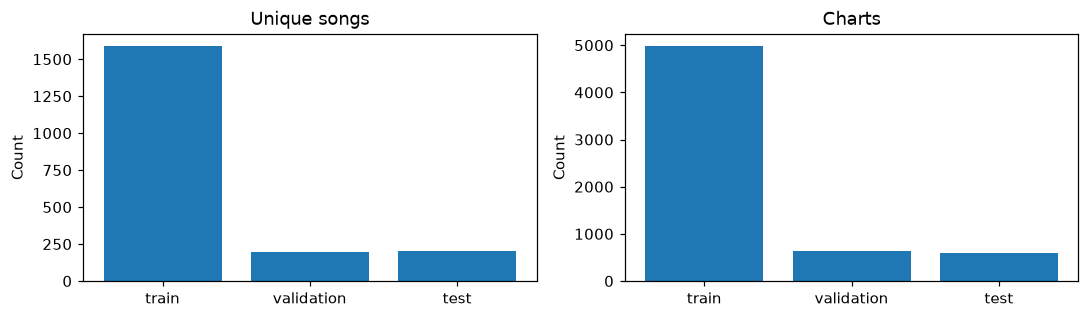

In [2]:
groups = {p: [r for r in rows if r["split"] == p] for p in PARTS}
assert all(r["split"] in PARTS for r in rows), "Unknown split"
audios = {p: {r["audio"] for r in group} for p, group in groups.items()}
for i, p in enumerate(PARTS):
    for q in PARTS[i + 1:]:
        assert audios[p].isdisjoint(audios[q]), f"Shared audio: {p}/{q}"
summary = []
for p in PARTS:
    summary.append({"split": p, "songs": len(audios[p]), "charts": len(groups[p])})
    print(summary[-1])
print("Total:", len({r["audio"] for r in rows}), "songs,", len(rows), "charts")
assert report["totals"]["kept_charts"] == len(rows)
assert report["totals"]["kept_songs"] == len({r["audio"] for r in rows})
with (OUT / "split_summary.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["split", "songs", "charts"])
    writer.writeheader()
    writer.writerows(summary)

def save(name):
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, key, title in zip(axes, ["songs", "charts"], ["Unique songs", "Charts"]):
    ax.bar(PARTS, [s[key] for s in summary])
    ax.set_title(title)
    ax.set_ylabel("Count")
save("split_sizes")


## Difficulty categories and levels


easy : 0 / 1354 missing levels
normal : 0 / 1357 missing levels
hard : 0 / 1526 missing levels
oni : 0 / 1763 missing levels
ura : 0 / 217 missing levels


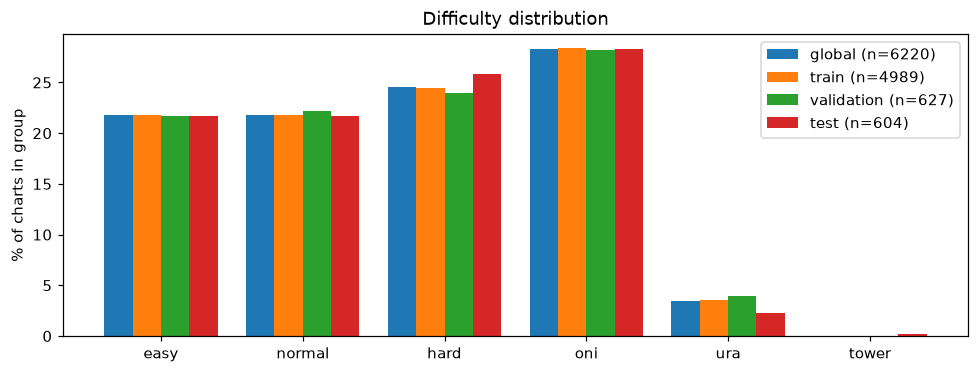

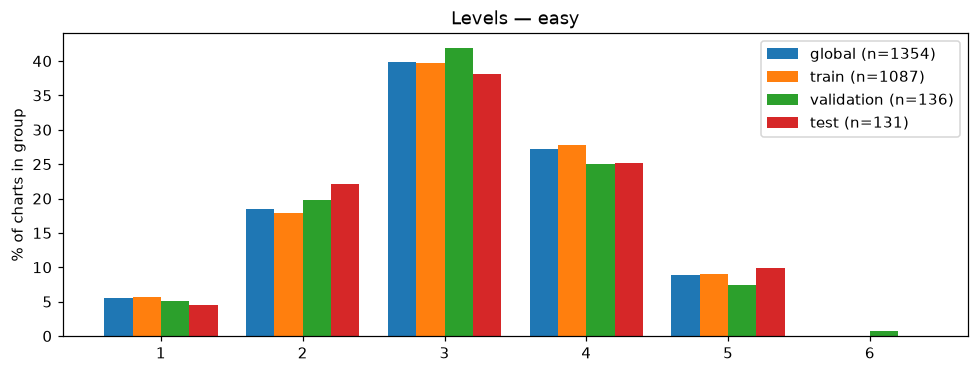

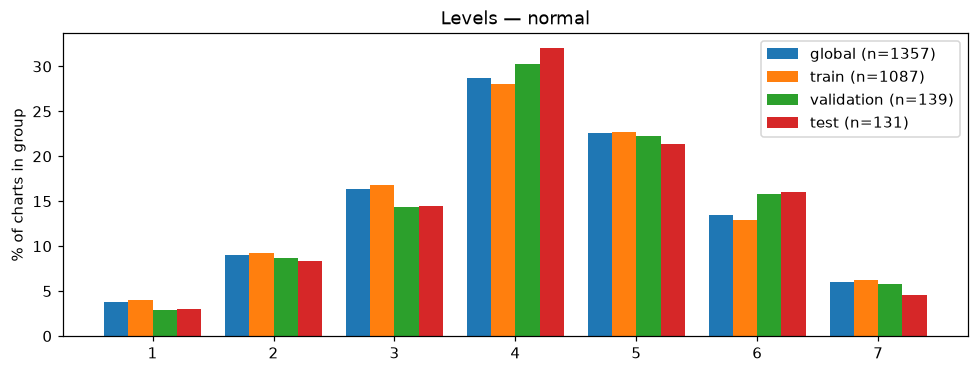

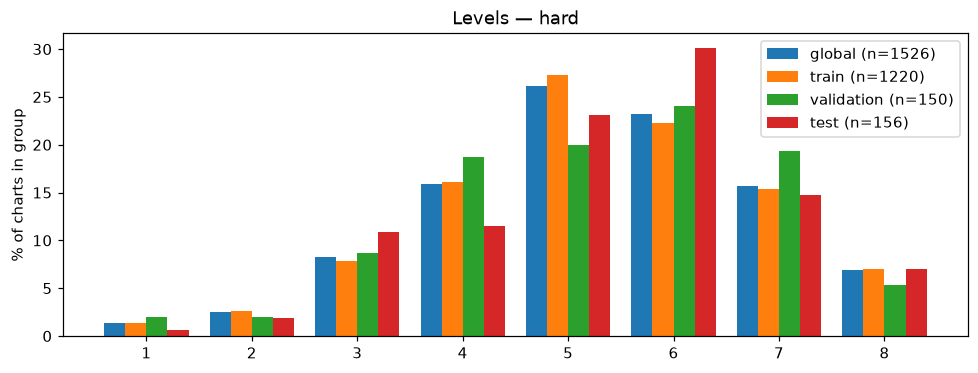

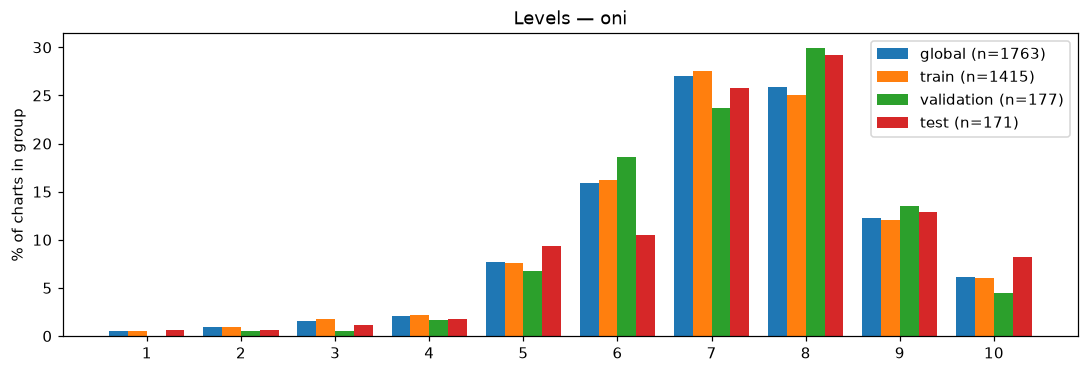

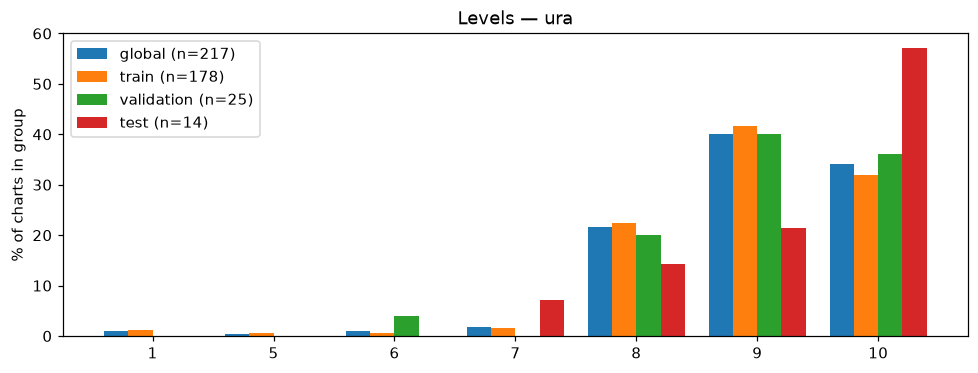

In [3]:
def compare_categories(key, categories, title, filename, selected=None):
    selected = rows if selected is None else selected
    sets = {"global": selected, **{p: [r for r in selected if r["split"] == p] for p in PARTS}}
    fig, ax = plt.subplots(figsize=(max(9, len(categories)), 3.5))
    x = np.arange(len(categories))
    width = 0.2
    for i, (name, group) in enumerate(sets.items()):
        counts = Counter(r.get(key) or "missing" for r in group)
        values = [100 * counts[c] / len(group) if group else 0 for c in categories]
        ax.bar(x + (i - 1.5) * width, values, width, label=f"{name} (n={len(group)})")
    ax.set_xticks(x, categories)
    ax.set_ylabel("% of charts in group")
    ax.set_title(title)
    ax.legend()
    save(filename)

categories = COURSES + sorted({r["course"] for r in rows} - set(COURSES))
compare_categories("course", categories, "Difficulty distribution", "courses")
for course in COURSES:
    selected = [r for r in rows if r["course"] == course]
    if not selected:
        continue
    levels = sorted({r["level"] for r in selected if r["level"]}, key=float)
    missing = sum(not r["level"] for r in selected)
    print(course, ":", missing, "/", len(selected), "missing levels")
    compare_categories("level", levels + (["missing"] if missing else []),
                       f"Levels — {course}", f"levels_{course}", selected)


## Note types


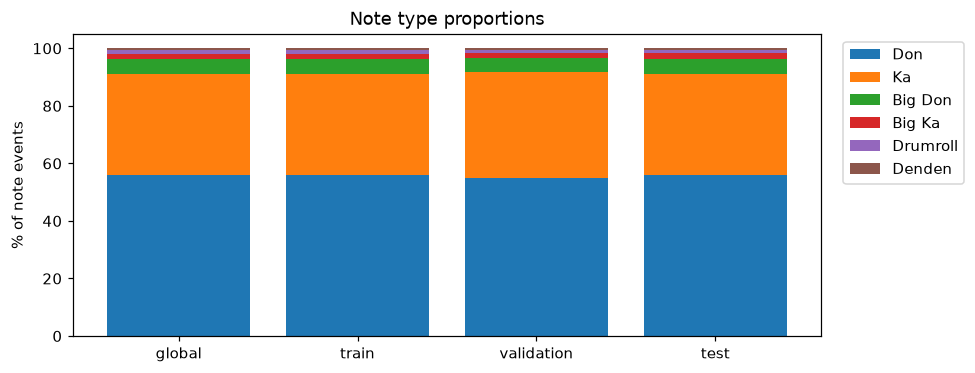

In [4]:
NOTE_TYPES = {"Don": "1", "Ka": "2", "Big Don": "3A", "Big Ka": "4B", "Drumroll": "56", "Denden": "79"}
def note_totals(group):
    return [sum(int(r.get(f"count_{c}") or 0) for r in group for c in codes)
            for codes in NOTE_TYPES.values()]

fig, ax = plt.subplots(figsize=(9, 3.5))
bottom = np.zeros(4)
all_groups = {"global": rows, **groups}
counts = np.array([note_totals(g) for g in all_groups.values()], dtype=float)
ratios = np.divide(100 * counts, counts.sum(axis=1, keepdims=True),
                   out=np.zeros_like(counts), where=counts.sum(axis=1, keepdims=True) != 0)
for i, label in enumerate(NOTE_TYPES):
    ax.bar(list(all_groups), ratios[:, i], bottom=bottom, label=label)
    bottom += ratios[:, i]
ax.set_ylabel("% of note events")
ax.set_title("Note type proportions")
ax.legend(bbox_to_anchor=(1.02, 1))
save("note_types")


## Note density


In [5]:
density_rows = []
if COMPUTE_DENSITY:
    from donderformer.data.audio import load_mono_audio
    durations = {}
    failures = {}
    for audio in sorted({r["audio"] for r in rows}):
        try:
            duration = len(load_mono_audio(paths.raw / audio, sr=8000)) / 8000
            if duration <= 0:
                raise ValueError("Empty audio")
            durations[audio] = duration
        except (OSError, ValueError, RuntimeError) as e:
            failures[audio] = str(e)
        except Exception as e:

            failures[audio] = f"{type(e).__name__}: {e}"
    for r in rows:
        if r["audio"] in durations:
            density_rows.append({"chart_id": r["chart_id"], "split": r["split"],
                                 "course": r["course"], "level": r["level"],
                                 "density": sum(note_totals([r])) / durations[r["audio"]]})
    (OUT / "audio_failures.json").write_text(json.dumps(failures, indent=2))
    print(len(density_rows), "/", len(rows), "charts with density;", len(failures), "failed audio files")
    if failures:
        print("First failure:", next(iter(failures.items())))
    if density_rows:
        with (OUT / "density.csv").open("w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=list(density_rows[0]))
            writer.writeheader()
            writer.writerows(density_rows)
elif (OUT / "density.csv").is_file():
    with (OUT / "density.csv").open(newline="", encoding="utf-8") as f:
        density_rows = list(csv.DictReader(f))
    assert len({r["chart_id"] for r in density_rows}) == len(density_rows), "Duplicate chart IDs in density cache"
    manifest_by_id = {r["chart_id"]: r for r in rows}
    for r in density_rows:
        assert r["chart_id"] in manifest_by_id, "Density cache does not match manifest"
        current = manifest_by_id[r["chart_id"]]
        assert all(r[key] == current[key] for key in ["split", "course", "level"]), "Stale density cache"
        r["density"] = float(r["density"])
        assert np.isfinite(r["density"]) and r["density"] >= 0, "Invalid density"
    print(f"Loaded cached density for {len(density_rows)} / {len(rows)} charts")
else:
    print("Density not computed: enable COMPUTE_DENSITY when audio files are available.")


Loaded cached density for 6220 / 6220 charts


global mean = 2.81 median = 2.46
train mean = 2.8 median = 2.45
validation mean = 2.81 median = 2.44
test mean = 2.88 median = 2.58


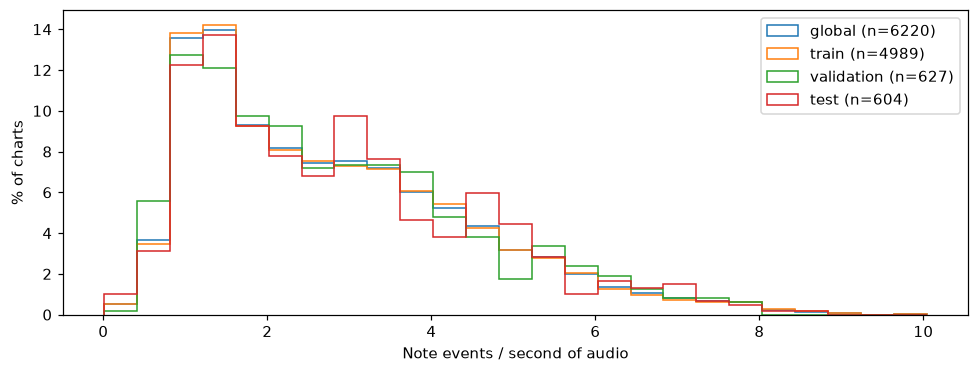

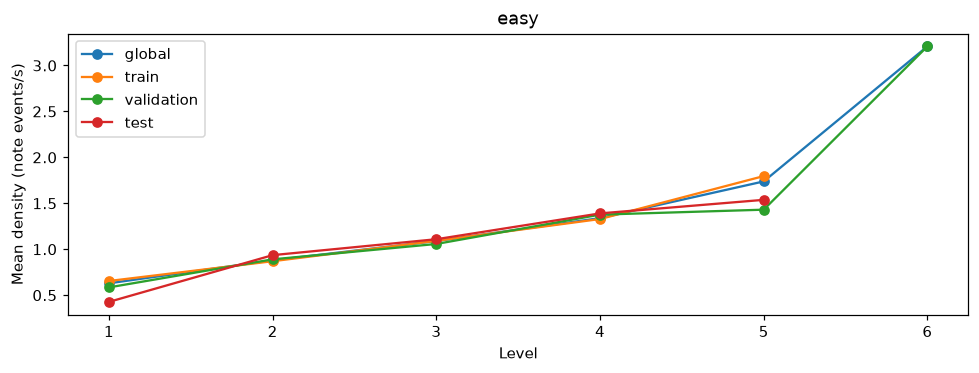

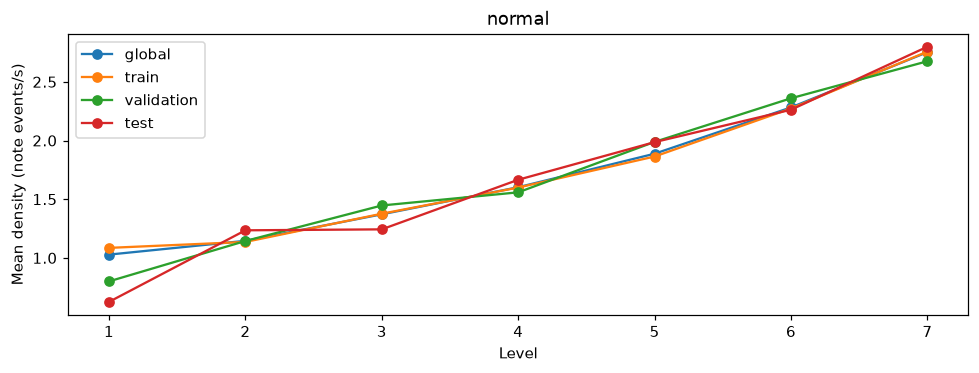

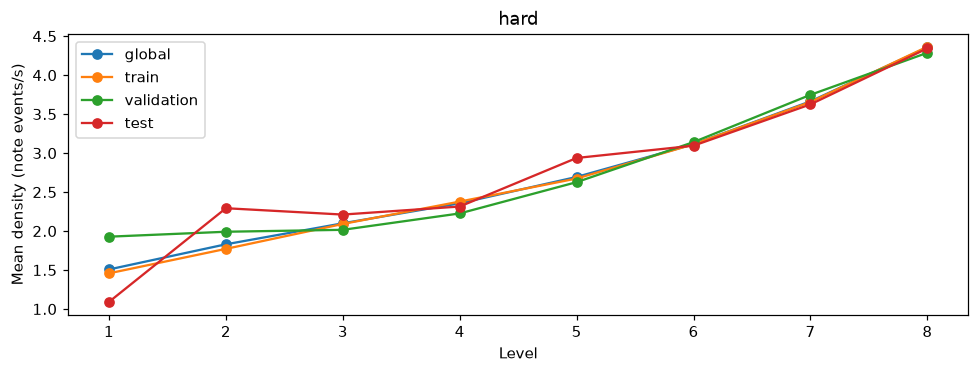

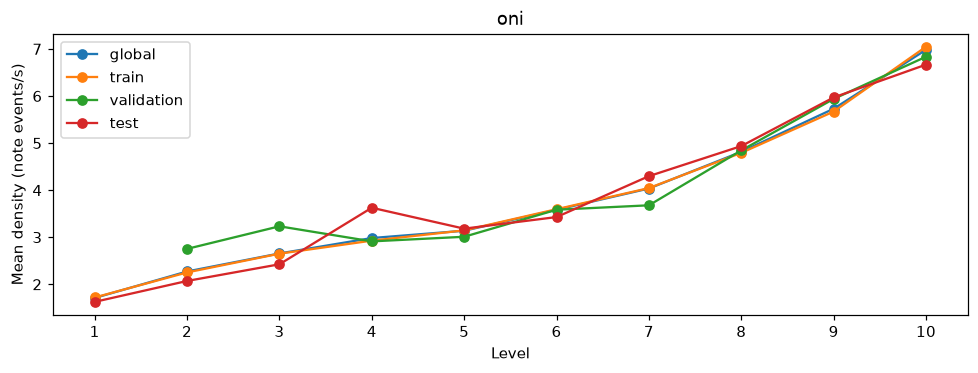

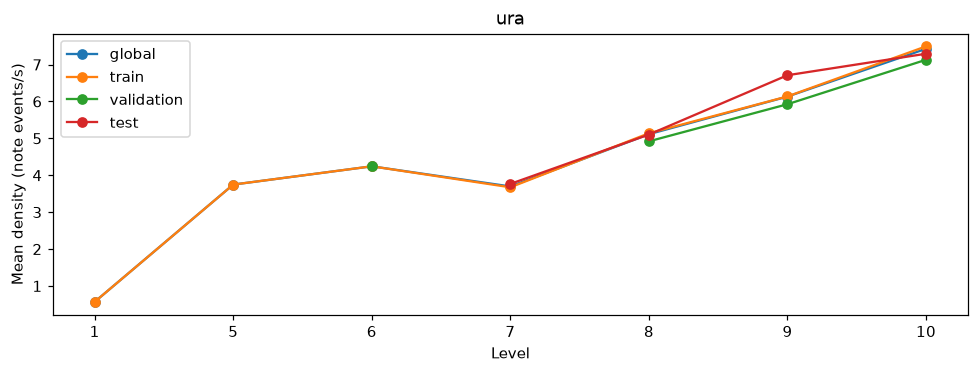

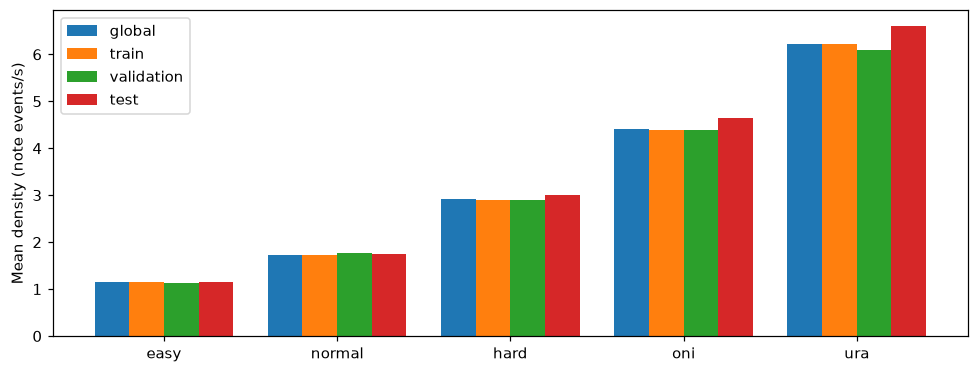

In [6]:
if density_rows:
    bins = np.histogram_bin_edges([r["density"] for r in density_rows], bins=25)
    fig, ax = plt.subplots(figsize=(9, 3.5))
    for name in ["global"] + PARTS:
        values = [r["density"] for r in density_rows if name == "global" or r["split"] == name]
        if values:
            ax.hist(values, bins=bins, weights=np.full(len(values), 100 / len(values)),
                    histtype="step", label=f"{name} (n={len(values)})")
            print(name, "mean =", round(float(np.mean(values)), 2),
                  "median =", round(float(np.median(values)), 2))
    ax.set_xlabel("Note events / second of audio")
    ax.set_ylabel("% of charts")
    ax.legend()
    save("density_histogram")
    for course in COURSES:
        selected = [r for r in density_rows if r["course"] == course and r["level"]]
        if not selected:
            continue
        levels = sorted({r["level"] for r in selected}, key=float)
        fig, ax = plt.subplots(figsize=(9, 3.5))
        for name in ["global"] + PARTS:
            values = [[r["density"] for r in selected if r["level"] == level
                       and (name == "global" or r["split"] == name)] for level in levels]
            means = [np.mean(v) if v else np.nan for v in values]
            ax.plot(levels, means, marker="o", label=name)
        ax.set_xlabel("Level")
        ax.set_ylabel("Mean density (note events/s)")
        ax.set_title(course)
        ax.legend()
        save(f"density_levels_{course}")

    fig, ax = plt.subplots(figsize=(9, 3.5))
    present = [c for c in COURSES if any(r["course"] == c for r in density_rows)]
    x = np.arange(len(present))
    for i, name in enumerate(["global"] + PARTS):
        values = [[r["density"] for r in density_rows if r["course"] == course
                   and (name == "global" or r["split"] == name)] for course in present]
        ax.bar(x + (i - 1.5) * .2, [np.mean(v) if v else np.nan for v in values], .2, label=name)
    ax.set_xticks(x, present)
    ax.set_ylabel("Mean density (note events/s)")
    ax.legend()
    save("density_courses")


## Scan coverage and filtering


In [7]:
for key in ["scanned_by_course", "usable_by_course", "lost_reasons"]:
    if key in report:
        print(key, report[key])
    else:
        print(key, ": not available in this report")


scanned_by_course {'easy': 2918, 'normal': 2909, 'hard': 2934, 'oni': 2874, 'ura': 399, 'dan': 100, 'tower': 20}
usable_by_course {'easy': 1354, 'hard': 1526, 'normal': 1357, 'oni': 1763, 'tower': 3, 'ura': 217}
lost_reasons {'bpm_change': 3818, 'nested_long_note': 2312, 'multiple_sections': 371, 'branching': 250, 'unsupported_command:#SECTION': 180, 'delay': 108, 'unsupported_command:#NEXTSONG': 100, 'note_inside_open_long_note': 45, 'unmatched_8': 37, 'unsupported_note::': 33, 'unsupported_note:E': 33, 'unsupported_note:M': 33, 'unsupported_note:X': 33, 'unsupported_note:m': 33, 'unsupported_note:r': 33, 'unsupported_command:#LYRIC': 26, 'unsupported_command:#LEVELHOLD': 8, 'unsupported_command:#SCROL': 2, 'unsupported_command:#GOGOEND\x81@': 1}


## Observations

The retained dataset contains **1,989 unique audio files and 6,220 charts**. A song can have several charts, one for each difficulty category. All charts sharing an audio file are assigned to the same split, and the overlap check found no shared audio paths between train, validation and test.

The split contains **1,591 / 198 / 200 songs** and **4,989 / 627 / 604 charts** for train / validation / test. The 80/10/10 target applies to songs, so chart counts do not have to follow exactly the same proportions.

### Difficulty categories and star levels

The main difficulty categories have similar proportions across splits. Easy and Normal each account for about 22% of the charts, Hard for 24–26%, and Oni for about 28%. Ura is less common: it represents 3.57% of training charts but only 2.32% of test charts.

Star levels describe variation within a difficulty category. Matching the number of Normal or Oni charts alone would not guarantee a comparable distribution of levels. Some differences remain: Hard level 6 accounts for 30.1% of test Hard charts versus 22.3% in training. Oni level 6 is less frequent in test (10.5%) than in training (16.2%).

Rare groups need care. The test set contains only **14 Ura charts**, including 8 at level 10. Results for this group may depend strongly on the particular songs selected. The single Easy level 6 chart is in validation and absent from training; its metadata should be checked before interpreting it as a representative group.

### Note types

Note type proportions are similar across splits. Don and Ka together account for about **91% of note events**. This imbalance is mainly a property of the retained dataset, rather than a large change introduced by the split. Similar overall proportions do not guarantee that every difficulty and level has the same note mix.

### Note density

Density is defined here as **playable note events divided by the full audio duration in seconds**. A long note counts once, at its start. Audio silence is included in the duration. This measures average chart density, rather than peak speed or every aspect of playing difficulty.

Density was computed for **all 6,220 retained charts, with no audio decoding failures**.

| Split | Charts | Mean density (events/s) | Median density (events/s) |
|---|---:|---:|---:|
| Train | 4,989 | 2.805 | 2.451 |
| Validation | 627 | 2.813 | 2.445 |
| Test | 604 | 2.876 | 2.576 |

The density histograms broadly overlap. Test density is slightly higher on average, but the plots do not show a large overall distribution shift. This is a descriptive comparison, not a statistical equivalence test.

Mean density increases across the main categories: **Easy 1.15, Normal 1.73, Hard 2.92, Oni 4.41 and Ura 6.23 events/s**. It also generally increases with star level. For example, across all splits, Oni level 3 averages approximately **2.65 events/s**, compared with **4.79 events/s** at level 8. This supports comparing levels within each category rather than treating all Oni charts as equally dense.

Differences at rare levels should be interpreted with their sample counts. A mean based on one or two charts is not a stable estimate of a whole level. Lines joining the means are visual guides; they do not imply that missing levels were observed.

### Scope and conclusion

The scanner found **12,154 charts**, retained **6,220** and rejected **5,934**. These plots describe the retained subset, not the complete raw dataset. Frequent rejection reasons include BPM changes and nested long notes. A chart can have multiple rejection reasons, so the reason counts cannot be added to obtain the number of rejected charts.

The current split broadly preserves difficulty categories, note type proportions and overall density. These checks do not provide a strong reason to replace it immediately. The main limitations are the small Ura test set, rare levels and parser filtering. Any later change to improve coverage should keep all charts sharing an audio file together and use a new split name. The audio-path overlap check does not detect duplicate recordings stored under different paths.
